# Part A: House Price Prediction (Regression)
Dataset: Egypt Houses Price (Kaggle). Target: `Price` (EGP).
Models: Linear Regression and KNN Regressor. Split: 70% train / 15% validation / 15% test (`random_state=42`).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42                           # same seed everywhere, so results can be repeated
pd.set_option("display.max_columns", 50)    # show every column
sns.set_theme(style="whitegrid")            # one clean plot style for the whole notebook

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.7.1


In [7]:
df = pd.read_csv("data/Egypt_Houses_Price.csv")

# Remove stray spaces around every value, e.g. "Unknown " -> "Unknown" and "Silva " -> "Silva"
for col in df.columns:
    df[col] = df[col].str.strip()

print(df.shape)
df.head()

(27361, 12)


,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
0,Duplex,4000000,3.0,3.0,400.0,No,7,Unknown,Cash,Ready to move,Finished,Nasr City
1,Apartment,4000000,3.0,3.0,160.0,No,10+,Unknown,Cash,Ready to move,Finished,Camp Caesar
2,Apartment,2250000,3.0,2.0,165.0,No,1,Unknown,Cash,Ready to move,Finished,Smoha
3,Apartment,1900000,3.0,2.0,230.0,No,10,Unknown,Cash,Ready to move,Finished,Nasr City
4,Apartment,5800000,2.0,3.0,160.0,No,Ground,Eastown,Cash,Ready to move,Semi Finished,New Cairo - El Tagamoa


### Where is data missing?

In [8]:
# Two kinds of missing: real empty cells (NaN) and the placeholder word "Unknown"
audit = pd.DataFrame({
    "nulls":   df.isna().sum(),
    "unknown": (df == "Unknown").sum(),
})
audit["pct_missing"] = ((audit["nulls"] + audit["unknown"]) / len(df) * 100).round(1)
audit.sort_values("pct_missing", ascending=False)

,nulls,unknown,pct_missing
Compound,0,11068,40.5
Level,0,10439,38.2
Delivery_Date,0,10108,36.9
Furnished,0,8528,31.2
Delivery_Term,0,4706,17.2
Area,471,36,1.9
Bedrooms,203,36,0.9
Bathrooms,171,36,0.8
Type,0,36,0.1
Price,2,37,0.1


In [9]:
# How many missing fields does each row have?
missing_per_row = (df == "Unknown").sum(axis=1) + df.isna().sum(axis=1)
missing_per_row.value_counts().sort_index()

0     5086
1     8931
2     6673
3     4103
4     1834
5      627
6       39
7       30
8        2
10      36
Name: count, dtype: int64

### Cleaning

In [10]:
print("Rows at start:", len(df))

# 1. Junk rows: scraper leftovers where every field is "Unknown" (not real houses)
df = df[df["Price"] != "Unknown"].copy()
print("After removing junk rows:", len(df))

# 2. Make the number columns real numbers (one value in Bedrooms and Bathrooms is "10+", we use 10)
for col in ["Price", "Bedrooms", "Bathrooms", "Area"]:
    df[col] = pd.to_numeric(df[col].replace("10+", "10"))

# 3. Merge spellings of the same type: "Twin house" -> "Twin House", "Stand Alone Villa" -> "Standalone Villa"
df["Type"] = df["Type"].str.title().replace("Stand Alone Villa", "Standalone Villa")

# 4. Remove rows with no Price (it is the target, we cannot learn from a house with no answer)
df = df.dropna(subset=["Price"])
print("After removing rows with no Price:", len(df))

# 5. Remove exact duplicates (done AFTER steps 2-3, so "3" and "3.0" now count as the same value)
before = len(df)
df = df.drop_duplicates()
print("Duplicates removed:", before - len(df))

# 6. Remove impossible values: prices under 100,000 EGP and areas under 20 m²
before = len(df)
df = df[df["Price"] >= 100_000]
print("Prices under 100,000 removed:", before - len(df))

before = len(df)
df = df[df["Area"].isna() | (df["Area"] >= 20)]   # keep empty Areas, we fill them later
print("Areas under 20 removed:", before - len(df))

df = df.reset_index(drop=True)
print("Final shape:", df.shape)

Rows at start: 27361
After removing junk rows: 27324
After removing rows with no Price: 27322
Duplicates removed: 1896
Prices under 100,000 removed: 56
Areas under 20 removed: 4
Final shape: (25366, 12)


In [11]:
df[["Price", "Bedrooms", "Bathrooms", "Area"]].describe().round(0)

,Price,Bedrooms,Bathrooms,Area
count,25366.0,25167.0,25199.0,24904.0
mean,4847392.0,3.0,3.0,231.0
std,6911355.0,1.0,1.0,162.0
min,100000.0,1.0,1.0,20.0
25%,1150000.0,3.0,2.0,125.0
50%,2800000.0,3.0,3.0,178.0
75%,6000000.0,4.0,4.0,276.0
max,240000000.0,10.0,10.0,998.0


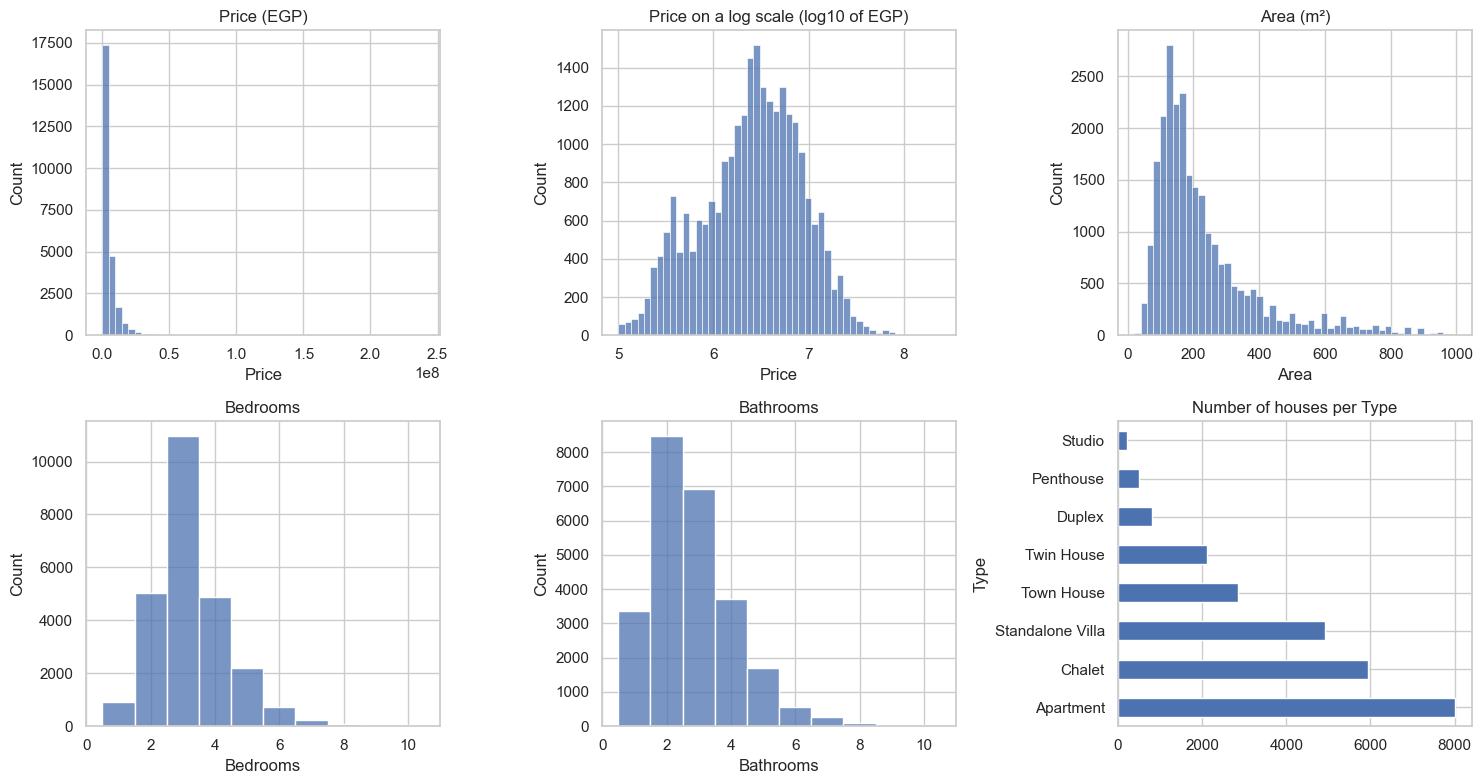

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

sns.histplot(df["Price"], bins=50, ax=axes[0, 0])
axes[0, 0].set_title("Price (EGP)")

sns.histplot(np.log10(df["Price"]), bins=50, ax=axes[0, 1])
axes[0, 1].set_title("Price on a log scale (log10 of EGP)")

sns.histplot(df["Area"], bins=50, ax=axes[0, 2])
axes[0, 2].set_title("Area (m²)")

sns.histplot(df["Bedrooms"], discrete=True, ax=axes[1, 0])
axes[1, 0].set_title("Bedrooms")

sns.histplot(df["Bathrooms"], discrete=True, ax=axes[1, 1])
axes[1, 1].set_title("Bathrooms")

df["Type"].value_counts().plot.barh(ax=axes[1, 2])
axes[1, 2].set_title("Number of houses per Type")

plt.tight_layout()
plt.show()

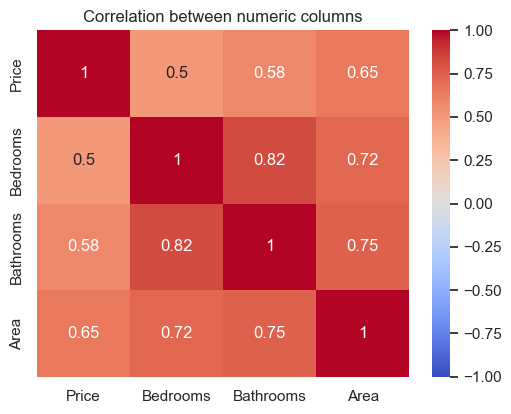

In [13]:
corr = df[["Price", "Bedrooms", "Bathrooms", "Area"]].corr()

plt.figure(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numeric columns")
plt.show()

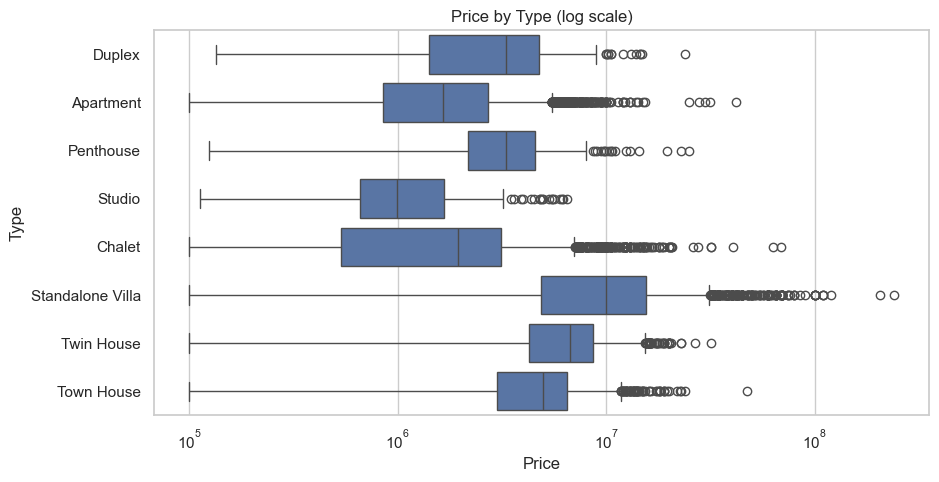

In [14]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Price", y="Type")
plt.xscale("log")          # log scale, otherwise the expensive houses squash everything else
plt.title("Price by Type (log scale)")
plt.show()

## Suspiciously cheap listings
Some prices look too low for the size of the house. We check price per m² and how the payment option is spread across price bands.

In [15]:
# Price per m². We keep it as a separate Series and NOT as a new column of df,
# because it is made from Price (the target) and would leak the answer into the features.
price_per_m2 = df["Price"] / df["Area"]

cheap = df[price_per_m2 < 1000]          # under 1,000 EGP per m²
print("Suspiciously cheap listings:", len(cheap))

print(cheap["Payment_Option"].value_counts())    # the cheap ones
print(df["Payment_Option"].value_counts())       # all houses, for comparison

cheap[["Type", "Price", "Area", "City", "Payment_Option"]].head(10)

Suspiciously cheap listings: 158
Payment_Option
Cash or Installment    71
Installment            50
Unknown Payment        31
Cash                    6
Name: count, dtype: int64
Payment_Option
Cash or Installment    9858
Cash                   8987
Installment            3638
Unknown Payment        2883
Name: count, dtype: int64


,Type,Price,Area,City,Payment_Option
614,Apartment,125800.0,180.0,6th of October,Installment
776,Apartment,110000.0,121.0,New Cairo - El Tagamoa,Cash or Installment
975,Apartment,129000.0,130.0,6th of October,Unknown Payment
1083,Apartment,110000.0,120.0,Nasr City,Cash
1215,Apartment,123000.0,165.0,Mostakbal City,Installment
1222,Apartment,122000.0,147.0,Mostakbal City,Installment
1234,Apartment,124000.0,141.0,Nasr City,Installment
1475,Duplex,324000.0,378.0,New Capital City,Installment
1725,Duplex,216000.0,270.0,New Capital City,Cash or Installment
1958,Apartment,123000.0,134.0,New Capital City,Installment


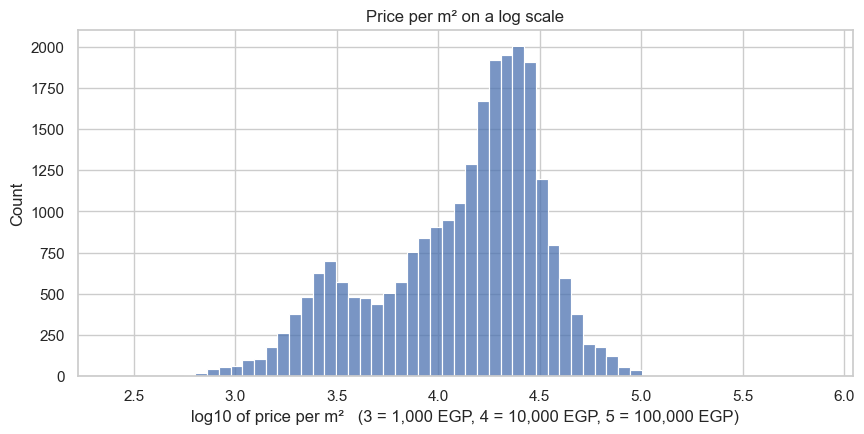

In [16]:
price_per_m2 = df["Price"] / df["Area"]      # separate Series, not a column of df (it is made from the target)
log_ppm = np.log10(price_per_m2.dropna())

plt.figure(figsize=(10, 4.5))
sns.histplot(log_ppm, bins=60)
plt.xlabel("log10 of price per m²   (3 = 1,000 EGP, 4 = 10,000 EGP, 5 = 100,000 EGP)")
plt.title("Price per m² on a log scale")
plt.show()

In [17]:
# How are the payment options spread across price-per-m² bands?
band = pd.cut(price_per_m2, [0, 1000, 2000, 3000, 4000, 5000, 7500, 10000, 20000, 1e9])
print(band.value_counts().sort_index())
pd.crosstab(band, df["Payment_Option"], normalize="index").round(2)

(0.0, 1000.0]               169
(1000.0, 2000.0]            901
(2000.0, 3000.0]           1743
(3000.0, 4000.0]           1190
(4000.0, 5000.0]            807
(5000.0, 7500.0]           1712
(7500.0, 10000.0]          1874
(10000.0, 20000.0]         6901
(20000.0, 1000000000.0]    9607
Name: count, dtype: int64


Payment_Option,Cash,Cash or Installment,Installment,Unknown Payment
row_0,,,,
"(0.0, 1000.0]",0.04,0.46,0.30,0.20
"(1000.0, 2000.0]",0.05,0.61,0.17,0.17
"(2000.0, 3000.0]",0.08,0.74,0.05,0.13
"(3000.0, 4000.0]",0.15,0.66,0.06,0.13
"(4000.0, 5000.0]",0.31,0.50,0.07,0.12
"(5000.0, 7500.0]",0.40,0.38,0.12,0.11
"(7500.0, 10000.0]",0.44,0.35,0.11,0.10
"(10000.0, 20000.0]",0.45,0.30,0.14,0.11
"(20000.0, 1000000000.0]",0.36,0.35,0.19,0.11


### What the data shows

I took price per m² on a log scale (the scale where it’s closest to a bell shape) and checked the payment mix in each price band.

It isn’t one bell. There’s a second, smaller hump around 2,000–3,000 EGP/m², then a dip near 4,000, and then the main hill, which peaks around 15,000–25,000.
The payment mix changes at the same spot. Below about 4,000 EGP/m², 72–81% of the houses are Installment or Cash or Installment and only 3–15% are Cash. From 5,000 EGP/m² upward, installments drop to about 44–49% and cash rises to 31–45%.
So the suspicious group is not just the 158 rows under 1,000. It’s roughly 4,000 rows (about 16%) below the dip.

### Three Options for Handling Price Outliers

| Option | Rule | Rows Removed | Trade-off |
|:---:|---|---:|---|
| **1** | Keep everything (only apply the 100,000 EGP price floor). | 0 | Simplest approach, but results in the noisiest target distribution. |
| **2** | **1.5 × IQR rule on log price per m²**, allowing values between 1,076 and 167,418 EGP/m². | 219 (0.9%) | Objective and statistically standard, but only trims the extreme tail. |
| **3** | Cut at the distribution's dip, approximately 4,000 EGP/m². | ~4,000 (16%) | Targets the broader cluster of unusually cheap listings, but risks removing genuinely affordable properties and teaching the model that cheap houses don't exist. |

### Decision: remove extreme price-per-m² values
We keep prices within the 1.5 x IQR range on the log scale (1,076 to 167,418 EGP per m²), which removes 219 rows.
Known limitation: a larger cluster of cheap listings (about 1,000 to 4,000 EGP per m²) remains. Most of them are installment listings, so their price may be a down payment, and the models will probably make large errors on them.

In [18]:
# 1.5 x IQR rule on the log scale (the same idea as the box plot, on the scale where the data is bell-shaped)
q1, q3 = log_ppm.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = 10 ** (q1 - 1.5 * iqr), 10 ** (q3 + 1.5 * iqr)
print(f"Allowed price per m²: {low:,.0f} to {high:,.0f} EGP")

keep = price_per_m2.isna() | ((price_per_m2 >= low) & (price_per_m2 <= high))   # keep rows with empty Area
print("Rows removed:", (~keep).sum())

df = df[keep].reset_index(drop=True)
print("Final shape:", df.shape)

Allowed price per m²: 1,076 to 167,418 EGP
Rows removed: 219
Final shape: (25147, 12)


In [25]:
bins = [0, 500_000, 1_000_000, 2_000_000, 3_000_000, 5_000_000, 10_000_000, 20_000_000, 50_000_000, 1e9]
labels = ["<0.5M", "0.5-1M", "1-2M", "2-3M", "3-5M", "5-10M", "10-20M", "20-50M", ">50M"]

price_range = pd.cut(df["Price"], bins=bins, labels=labels)
counts = price_range.value_counts().sort_index()
pd.DataFrame({"houses": counts, "share_%": (counts / len(df) * 100).round(1)})

,houses,share_%
Price,,
<0.5M,3146,12.5
0.5-1M,2584,10.3
1-2M,4074,16.2
2-3M,3583,14.2
3-5M,4139,16.5
5-10M,4657,18.5
10-20M,2244,8.9
20-50M,655,2.6
>50M,65,0.3


only 2.9% of houses cost more than 20M EGP (2.6% in 20–50M plus 0.3% above 50M), and just 65 houses cost more than 50M.

quartiles and fences per Type

In [26]:
# Q1, median, Q3 of Price for each Type; the IQR is Q3 - Q1.
# The upper fence (Q3 + 1.5 x IQR) is the box-plot limit: prices above it count as outliers.
q = df.groupby("Type")["Price"].quantile([0.25, 0.5, 0.75]).unstack()
q.columns = ["Q1", "median", "Q3"]
q["IQR"] = q["Q3"] - q["Q1"]
q["upper_fence"] = q["Q3"] + 1.5 * q["IQR"]

q["houses"] = df["Type"].value_counts()
q["above_fence"] = (df["Price"] > df["Type"].map(q["upper_fence"])).groupby(df["Type"]).sum()
q["share_above_%"] = (q["above_fence"] / q["houses"] * 100).round(1)

table = q[["Q1", "median", "Q3", "IQR", "upper_fence"]] / 1e6      # in million EGP
table[["houses", "above_fence", "share_above_%"]] = q[["houses", "above_fence", "share_above_%"]]
table.round(2)

,Q1,median,Q3,IQR,upper_fence,houses,above_fence,share_above_%
Type,,,,,,,,
Apartment,0.85,1.65,2.71,1.86,5.50,7924,281,3.5
Chalet,0.54,1.95,3.14,2.60,7.04,5922,213,3.6
Duplex,1.50,3.30,4.75,3.25,9.62,806,13,1.6
Penthouse,2.18,3.30,4.54,2.35,8.07,503,17,3.4
Standalone Villa,5.00,10.00,15.50,10.50,31.25,4876,211,4.3
Studio,0.66,0.99,1.68,1.02,3.20,220,18,8.2
Town House,3.15,5.00,6.50,3.35,11.52,2795,69,2.5
Twin House,4.37,6.75,8.70,4.33,15.20,2101,57,2.7


the fences differ enormously by Type. Apartment is 5.5M and Standalone Villa is 31.3M. A villa’s Q1 (5.0M) is almost the apartment fence (5.5M), so a cutoff that suits apartments would delete most villas. One price cutoff for all houses can’t be justified.

The flagged share is steady: between 1.6% and 8.2% of every Type sits above its fence. That is what a long right tail looks like. If these were typos, we’d expect them to be scattered unevenly. Eventhough, they are still outliers and impact the model heavily.

box plots per Type, raw and log scale

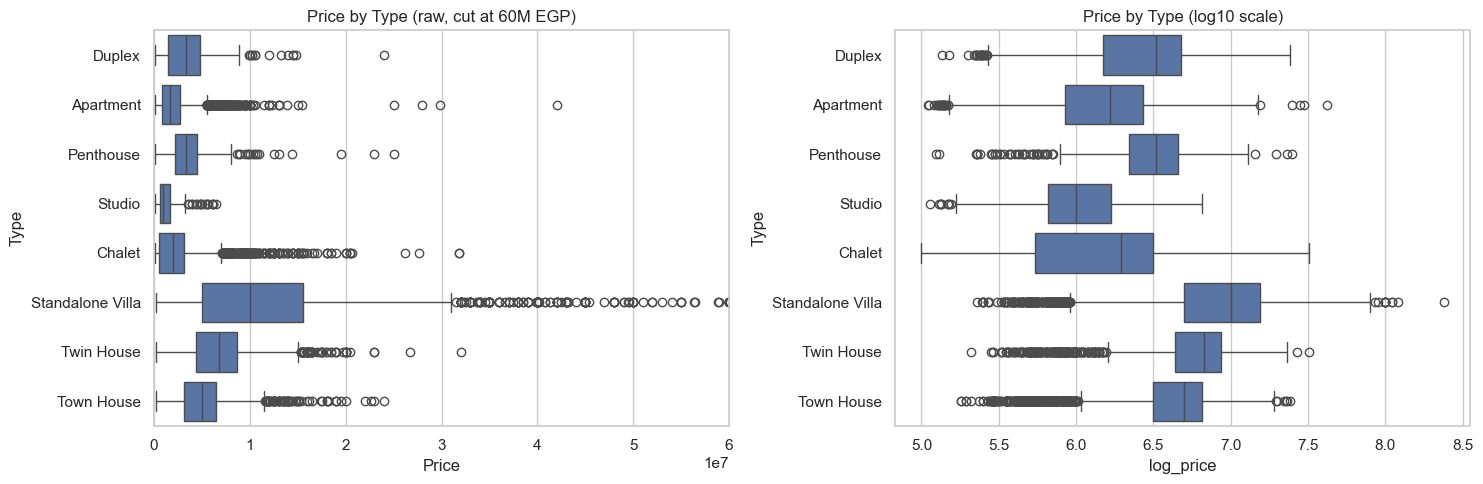

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df, x="Price", y="Type", ax=axes[0])
axes[0].set_xlim(0, 60_000_000)                      # cut at 60M so the boxes are visible
axes[0].set_title("Price by Type (raw, cut at 60M EGP)")

sns.boxplot(data=df.assign(log_price=np.log10(df["Price"])), x="log_price", y="Type", ax=axes[1])
axes[1].set_title("Price by Type (log10 scale)")

plt.tight_layout()
plt.show()

In [28]:
# Remove houses priced above the upper fence of their OWN Type (Q3 + 1.5 x IQR, from Cell F)
above_fence = df["Price"] > df["Type"].map(q["upper_fence"])

print("Houses removed per Type:")
print(above_fence.groupby(df["Type"]).sum())
print("Total removed:", above_fence.sum(), f"({above_fence.mean():.1%})")

df = df[~above_fence].reset_index(drop=True)
print("Final shape:", df.shape)

Houses removed per Type:
Type
Apartment           281
Chalet              213
Duplex               13
Penthouse            17
Standalone Villa    211
Studio               18
Town House           69
Twin House           57
dtype: int64
Total removed: 879 (3.5%)
Final shape: (24268, 12)


## Outlier analysis: expensive houses
**Question:** should houses with extreme prices be removed before modelling?

**Evidence**
- Prices are strongly right-skewed: 2.9% of houses cost more than 20M EGP and 0.3% (65 houses) more than 50M EGP.
- Typical prices differ a lot between Types (upper fence: Apartment 5.5M, Standalone Villa 31.3M EGP), so one cutoff for all houses would be unfair. We use each Type's own box-plot fence (Q3 + 1.5 x IQR).
- Between 1.6% and 8.2% of the houses of each Type lie above its fence.
- Extreme prices have a large pull on squared-error metrics such as RMSE and on Linear Regression.
- Rows where price and size contradicted each other were already removed (price per m² rule).

**Decision:** remove houses priced above the upper fence of their Type before splitting the data (879 houses, 3.5%).

**Limitation:** the models and every score reported below apply to houses whose price is typical for their Type. Very expensive listings (mostly luxury villas) are outside the scope of the model, and scores are not directly comparable with a model evaluated on all houses, because the evaluation set is easier without them. The fences were computed on the full dataset before the split; this is a data-cleaning rule, not something the model learns.

## Cleaning decisions log
| Step | Rows removed | Reason |
|---|---|---|
| Junk rows (every field "Unknown") | 37 | Scraper leftovers, not houses |
| Missing Price | 2 | No target to learn from |
| Exact duplicates (after fixing formats) | 1,896 | Same listing scraped repeatedly |
| Price under 100,000 EGP | 56 | Implausible prices |
| Area under 20 m² | 4 | Implausible areas |
| Price per m² outside 1,076 to 167,418 EGP (1.5 x IQR, log scale) | 219 | Price inconsistent with size |
| Price above the upper fence of its Type | 879 | Extreme prices, scope of the model |
| **Total** | **3,093** | 27,361 rows -> 24,268 rows |

In [29]:
X = df.drop(columns="Price")     # features: everything except the answer
y = df["Price"]                  # target: what we want to predict

# First take 70% for training, then split the remaining 30% in half: 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE)

print("Train:", len(X_train), " Validation:", len(X_val), " Test:", len(X_test))

Train: 16987  Validation: 3640  Test: 3641


In [30]:
numeric_cols = ["Bedrooms", "Bathrooms", "Area"]
categorical_cols = ["Type", "Furnished", "Level", "Compound", "Payment_Option",
                    "Delivery_Date", "Delivery_Term", "City"]

# Numbers: fill empty cells with the median, add a 0/1 "was missing" column, then scale
numeric_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])

# Categories: one 0/1 column per category.
# Categories with fewer than 50 houses in the training data are grouped into one "infrequent" column.
categorical_step = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50)

preprocess = ColumnTransformer([
    ("numeric", numeric_steps, numeric_cols),
    ("categorical", categorical_step, categorical_cols),
])

In [31]:
X_train_ready = preprocess.fit_transform(X_train)    # learns medians, scaling and categories from TRAIN only
print("Before:", X_train.shape, " After:", X_train_ready.shape)

names = list(preprocess.get_feature_names_out())
print(names[:8])
print(names[-6:])

Before: (16987, 11)  After: (16987, 126)
['numeric__Bedrooms', 'numeric__Bathrooms', 'numeric__Area', 'numeric__missingindicator_Bedrooms', 'numeric__missingindicator_Bathrooms', 'numeric__missingindicator_Area', 'categorical__Type_Apartment', 'categorical__Type_Chalet']
['categorical__City_Rehab City', 'categorical__City_Sheikh Zayed', 'categorical__City_Shorouk City', 'categorical__City_Smoha', 'categorical__City_Zahraa Al Maadi', 'categorical__City_infrequent_sklearn']


### Why These Preprocessing Choices?

- **Median, not mean, for missing numerical values.** The median is less affected by extreme values. The *missingness indicator* columns preserve information about which values were originally empty. This matters particularly for villas, which have the highest frequency of missing `Area` values.

- **Scaling** puts `Area` (ranging from 20 to 998) on a comparable scale with the 0/1 encoded columns. KNN needs scaling because it relies on distances, as my testing demonstrated. Linear Regression can also work with scaled features.

- **`min_frequency=50`** handles high-cardinality categorical columns without requiring additional manual encoding. `City` has 178 unique values and `Compound` has 559, but in my run, only 26 cities and 48 compounds receive their own columns. The remaining less-frequent categories are grouped into an `"infrequent"` category.

In [32]:
# A Pipeline chains the steps: preprocessing first, then the model.
# fit() learns everything from the training data; predict() applies the same steps to new houses.
linreg = Pipeline([("preprocess", preprocess), ("model", LinearRegression())])
linreg.fit(X_train, y_train)

val_pred = linreg.predict(X_val)

print("Linear Regression on the validation set")
print("MAE :", round(mean_absolute_error(y_val, val_pred)))
print("RMSE:", round(np.sqrt(mean_squared_error(y_val, val_pred))))
print("R²  :", round(r2_score(y_val, val_pred), 3))
print("Negative predicted prices:", (val_pred < 0).sum(), "of", len(val_pred))

Linear Regression on the validation set
MAE : 1799272
RMSE: 2848726
R²  : 0.647
Negative predicted prices: 119 of 3640


 k       MAE      RMSE    R2
 1 1692153.0 3168673.0 0.563
 3 1545871.0 2709119.0 0.681
 5 1558099.0 2669009.0 0.690
 7 1563369.0 2668537.0 0.690
 9 1547697.0 2639676.0 0.697
11 1551367.0 2640157.0 0.697
15 1578312.0 2676966.0 0.688
21 1610830.0 2713009.0 0.680
31 1635493.0 2729936.0 0.676
41 1660462.0 2761636.0 0.668
51 1678409.0 2783056.0 0.663


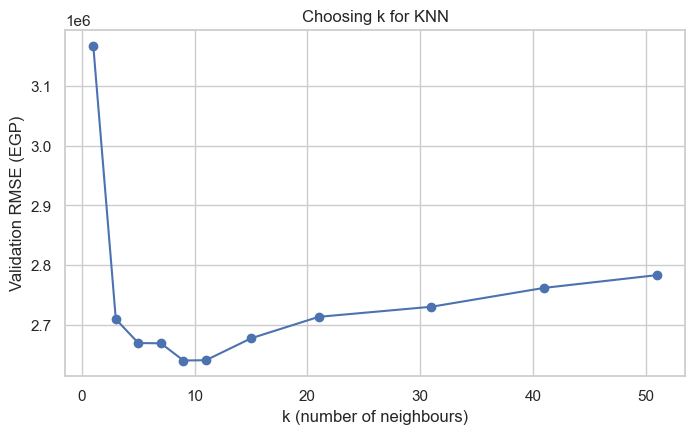

In [33]:
# For each k: fit on the training set, measure the error on the VALIDATION set
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 51]
rows = []

for k in k_values:
    knn = Pipeline([("preprocess", preprocess), ("model", KNeighborsRegressor(n_neighbors=k))])
    knn.fit(X_train, y_train)
    pred = knn.predict(X_val)
    rows.append([k,
                 mean_absolute_error(y_val, pred),
                 np.sqrt(mean_squared_error(y_val, pred)),
                 r2_score(y_val, pred)])

results = pd.DataFrame(rows, columns=["k", "MAE", "RMSE", "R2"])
print(results.round({"MAE": 0, "RMSE": 0, "R2": 3}).to_string(index=False))

plt.figure(figsize=(8, 4.5))
plt.plot(results["k"], results["RMSE"], marker="o")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Validation RMSE (EGP)")
plt.title("Choosing k for KNN")
plt.show()

In [34]:
best_k = int(results.loc[results["RMSE"].idxmin(), "k"])    # k with the lowest validation RMSE
print("Best k by RMSE:", best_k)

Best k by RMSE: 9


build the KNN with k=9

In [35]:
best_knn = Pipeline([("preprocess", preprocess), ("model", KNeighborsRegressor(n_neighbors=best_k))])
best_knn.fit(X_train, y_train)      # trained on the training set only

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Lets do Some analysis on the Validation results

errors by price group

In [36]:
# Predictions and errors on the VALIDATION set (error > 0 means we predicted too high)
val_pred_lr  = linreg.predict(X_val)
val_pred_knn = best_knn.predict(X_val)

errors = pd.DataFrame({"actual": y_val, "pred_knn": val_pred_knn, "pred_lr": val_pred_lr})
errors["error_knn"] = errors["pred_knn"] - errors["actual"]
errors["error_lr"]  = errors["pred_lr"]  - errors["actual"]
errors["abs_error_knn"] = errors["error_knn"].abs()
errors["abs_error_lr"]  = errors["error_lr"].abs()

# Group the houses by how expensive they really are (the last groups are the top 10%, 5% and 1%)
errors["price_group"] = pd.qcut(errors["actual"], [0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1])

# Average price and errors per group, in million EGP
summary = errors.groupby("price_group", observed=True)[
    ["actual", "error_knn", "abs_error_knn", "error_lr", "abs_error_lr"]].mean() / 1e6
summary.insert(0, "houses", errors["price_group"].value_counts().sort_index())
summary.round(2)

,houses,actual,error_knn,abs_error_knn,error_lr,abs_error_lr
price_group,,,,,,
"(110999.999, 1150000.0]",911,0.58,1.09,1.11,1.17,1.48
"(1150000.0, 2600000.0]",910,1.84,0.34,0.76,0.42,1.18
"(2600000.0, 5500000.0]",934,3.88,-0.13,1.34,0.06,1.46
"(5500000.0, 10000000.0]",531,7.39,-0.02,2.14,0.11,2.10
"(10000000.0, 14000000.0]",178,12.18,-1.08,2.73,-1.17,2.31
"(14000000.0, 25000000.0]",148,18.62,-4.48,4.91,-5.63,5.78
"(25000000.0, 31000000.0]",28,27.71,-11.34,11.34,-13.50,13.50


where does the squared error come from?

In [37]:
top5 = errors["actual"] >= errors["actual"].quantile(0.95)
share = (errors.loc[top5, "error_knn"] ** 2).sum() / (errors["error_knn"] ** 2).sum()
print(f"The most expensive 5% of houses cause {share:.0%} of the squared error (RMSE) for KNN")

The most expensive 5% of houses cause 40% of the squared error (RMSE) for KNN


the 10 worst predictions

In [38]:
worst = errors.join(X_val[["Type", "City", "Compound", "Area", "Bedrooms"]])
worst = worst.sort_values("abs_error_knn", ascending=False)
worst.head(10)[["Type", "City", "Compound", "Area", "Bedrooms", "actual", "pred_knn"]].round(0)

,Type,City,Compound,Area,Bedrooms,actual,pred_knn
13182,Standalone Villa,North Coast,Unknown,395.0,3.0,27000000.0,4672000.0
12679,Standalone Villa,North Coast,Unknown,475.0,5.0,26000000.0,7019667.0
19919,Standalone Villa,Rehab City,Madinaty,425.0,5.0,25000000.0,6277778.0
21410,Standalone Villa,New Cairo - El Tagamoa,Swan Lake,420.0,4.0,27700000.0,10395556.0
22690,Standalone Villa,New Cairo - El Tagamoa,Unknown,NaN,6.0,30000000.0,12738889.0
14797,Standalone Villa,North Coast,Unknown,420.0,6.0,29000000.0,12072222.0
17437,Standalone Villa,New Cairo - El Tagamoa,Al Yasmine,645.0,7.0,850000.0,17111111.0
20495,Standalone Villa,Sheikh Zayed,Allegria,570.0,4.0,28000000.0,12233333.0
10378,Standalone Villa,North Coast,Marassi,602.0,5.0,31000000.0,15566667.0
20063,Standalone Villa,Hadayek al-Ahram,Unknown,784.0,5.0,1300000.0,16666667.0


20063 and 17437 are diffinitely typos, and the 10 worst predictions are all standalone villas, 645 m² at 850,000 EGP (1,318 EGP/m²) and 784 m² at 1,300,000 EGP (1,658 EGP/m²). A typical villa costs about 20,000 EGP/m², so these are about 1/15 of normal.

### Known issue: the price-per-m² rule is too lenient for some Types
The first price-per-m² rule used one lower fence for all houses: 1,076 EGP per m². That fence is dominated by apartments (median about 10,500 EGP per m²), so it is far too lenient for villas (median about 20,000). The fence for villas on their own is 2,428, which would catch the two typos found in the worst validation errors (a 645 m² villa at 850,000 EGP and a 784 m² villa at 1,300,000 EGP).

We will not delete those two rows by hand: removing rows because we saw them in the validation errors would mean tuning the data to the validation set. The defensible fix is a general rule applied to every row, so the global rule will be replaced by the same rule applied separately for each Type.